# Charter diplomatic segmentation – Demo

This notebook shows what [`ERCDiDip/charter-diplomatic-segmentation`](https://huggingface.co/ERCDiDip/charter-diplomatic-segmentation) ("segmenter-tiny") can do.
The model assigns every word of a **medieval Latin or Middle High German charter** to one of **11 diplomatic sections**
(*invocatio, intitulatio, arenga, publicatio, narratio, dispositio, sanctio, corroboratio, subscriptio, datatio, apprecatio*).

* Model: Multilingual-MiniLM-L12-H384 token classifier (117 M parameters), distilled from an XLM-RoBERTa-base teacher; CC BY-NC 4.0
* Wrapper used here: `charter_segmenter.py` (windowed inference, word-level voting, span smoothing, HTML view)
* Demo charters: a 10th-century imperial diploma, a Hungarian royal mandate (1416), a Middle High German mandate of Charles IV and a long Apulian notarial instrument (1417)

Requirements: `pip install torch transformers huggingface_hub pandas matplotlib` (first run downloads 470 MB of weights; a GPU is optional).

## 1. Load the model

In [1]:
import time, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import pandas as pd
from IPython.display import HTML, display

from charter_segmenter import (CharterSegmenter, to_html, collapse_spans, smooth_spans,
                               SECTION_ORDER, SECTION_GLOSS, SECTION_COLORS)

seg = CharterSegmenter()   # picks the GPU automatically if available
print(f"{len(seg.labels)} labels, {len(seg.sections)} sections, device: {seg.device}")

[1/2] Loading tokenizer and weights from ERCDiDip/charter-diplomatic-segmentation (downloaded once, cached afterwards) ...


[2/2] Moving the model to cuda ...


22 labels, 11 sections, device: cuda


## 2. The eleven sections
The checkpoint has 22 labels: a `B-` and an `I-` label for each section and **no outside class**, so every word belongs to some section.
The label order in the checkpoint config is alphabetical; the wrapper reads it from the config and presents the sections in diplomatic order.

In [2]:
def paint(col):
    return [f"background-color: {SECTION_COLORS[s]}" for s in col]

sections = pd.DataFrame({"section": SECTION_ORDER, "description": [SECTION_GLOSS[s] for s in SECTION_ORDER]})
sections.style.apply(paint, subset=["section"]).hide(axis="index")

section,description
INVOCATIO,invocation of God (In nomine ...)
INTITULATIO,name and title of the issuer
ARENGA,preamble with general moral or religious motivation
PUBLICATIO,"announcement to the public (Notum sit ..., Wir tun kund ...)"
NARRATIO,narration of the circumstances that led to the act
DISPOSITIO,"the legal act itself (grant, confirmation, order ...)"
SANCTIO,penalty or threat against violators
CORROBORATIO,"announcement of the means of authentication (seal, witnesses)"
SUBSCRIPTIO,subscriptions and witness list
DATATIO,date and place of issue


## 3. A classic imperial diploma: Otto I for Negomir (Freising B 33)
The text is the plain tenor of `FreisBm/0965_IV_03.cei.xml` from the public
[Structurally Annotated Medieval Charters](https://github.com/AlinaOs/Structurally_Annotated_Medieval_Charters) corpus (Ostrowski 2021),
reproduced verbatim, including the transcription errors and the editor's `(!)` marks of the Monasterium.net file.

This corpus is part of the teacher's training data, so this section illustrates the **label scheme on an in-sample text**; it is not an evaluation.
The three charters in sections 4–6 are outside the training corpora.

`min_span_words=0` returns the raw spans without smoothing.

In [3]:
def show(spans, width=110):
    for sp in spans:
        t = sp["text"] if len(sp["text"]) <= width else sp["text"][:width - 3] + "..."
        print(f'{sp["section"]:<13} {sp["n_words"]:>3} words  conf {sp["conf"]:.2f}  {t}')

otto = open("Otto_965_IV_03_FreisBm_diploma.txt", encoding="utf-8").read().strip()
otto_raw = seg.predict(otto, min_span_words=0)
show(otto_raw)
display(HTML(to_html(otto, otto_raw, title="Otto I for Negomir (Monasterium.net FreisBm 0965_IV_03)")))

INVOCATIO       7 words  conf 0.59  C. In nomine sanctae et indiuiduae trinitatis.
INTITULATIO     6 words  conf 0.93  Otto diuina annuente clementia imperator augustus.
PUBLICATIO      8 words  conf 0.94  Nouerint omnes fideles nostri praesentes scilicet et futuri,
NARRATIO       25 words  conf 0.81  qualiter nos per interuentum dilecte ducis (!) domineque Judite, nee non oratu riobis satis cari episcopi A...
DISPOSITIO     86 words  conf 1.00  proprietatem, qualem nos visi sumus habere ad Vuirzsosah in partibus Carantanie in comitatu Hartuuigi comit...
CORROBORATIO   18 words  conf 0.98  Et vt haec nostre donationis auetoritas firma permaneat, anuli nostri impressione sigillari iussimus manu n...
SUBSCRIPTIO    13 words  conf 0.49  Signum domni Ottonis (M) pigissimi (!) imperatoris.Liutulfus notarius ad uicem Brunonis arcbicapellani reco...
DATATIO        22 words  conf 0.97  Data iii. nonas Apriles anno vero dominice incarnationis DCCCC.LXV., indictione VIII., imperante rero piiss..

### Raw versus smoothed spans
The model card's decoding recipe merges spans shorter than five words into the preceding span and then merges equal neighbours.
This removes one-word fragments at section boundaries (see section 6), but it also swallows genuinely short sections:
here the closing *amen* (`APPRECATIO`, one word) disappears into the `DATATIO`.

In [4]:
for m in (0, 5):
    spans = seg.predict(otto, min_span_words=m)
    print(f"min_span_words={m}: {len(spans)} spans ->", " | ".join(sp["section"] for sp in spans))

min_span_words=0: 9 spans -> INVOCATIO | INTITULATIO | PUBLICATIO | NARRATIO | DISPOSITIO | CORROBORATIO | SUBSCRIPTIO | DATATIO | APPRECATIO
min_span_words=5: 8 spans -> INVOCATIO | INTITULATIO | PUBLICATIO | NARRATIO | DISPOSITIO | CORROBORATIO | SUBSCRIPTIO | DATATIO


## 4. A royal mandate outside the training domain: Sigismund to the abbot of Tihany (1416)
A Latin mandate of the Hungarian royal chancery (`PannHActa_1416_VIII_10_charter.txt`), a text type and period that the training corpora do not contain.
The scheme has no *inscriptio* or *salutatio*, so the address *fideli nostro dilecto ... salutem et graciam* is absorbed by the `INTITULATIO`.

In [5]:
sig = open("PannHActa_1416_VIII_10_charter.txt", encoding="utf-8").read().strip()
sig_words = seg.predict_words(sig)
sig_spans = smooth_spans(collapse_spans(sig_words), 5)
print(f"{len(sig_words)} words, {len(sig_spans)} spans")
display(HTML(to_html(sig, sig_spans, title="Sigismund to Demetrius, abbot of Tihany, 1416 Aug 10")))

403 words, 8 spans


### Span table

In [6]:
df = pd.DataFrame(sig_spans)[["section", "n_words", "conf", "text"]]
df["text"] = df["text"].str.slice(0, 120)
df.style.format({"conf": "{:.2f}"}).apply(paint, subset=["section"]).hide(axis="index")

section,n_words,conf,text
INTITULATIO,29,0.93,"Sigismundus, Dei gracia Romanorum rex semper augustus ac Hungarie, Croacie etc. fideli nostro dilecto, venerabili et rel"
NARRATIO,57,0.80,"porrecta honorabilis domini Nicolai Georgii de Nariag, canonici ecclesie Wesprimiensis, in personis honorabilium virorum"
DISPOSITIO,182,0.87,"et litteras apostolicas nos per fatum Constanciense concilium procuravimus revocari, vigoribus decimas et quartas decima"
PUBLICATIO,12,0.81,"aliarum et eciam presencium litterarum nostrarum regalium seriebus fideli nostro dilecto, reverendissimo"
NARRATIO,39,0.75,"in Christo patri domino Ioanni, archiepiscopo Strigoniensi, aule nostre Romanoregie summo cancellario necnon regni nostr"
DISPOSITIO,49,0.91,"spiritualibus generali constitutis et constituendis commisimus et committimus, ut ipsi contumacia et rebellione vestris"
CORROBORATIO,5,0.67,leccionem semper reddi volumus presentanti.
DATATIO,30,0.98,Datum in civitate Landoniarum in regno Anglie in festo Sancti Laurencii martiris anno Domini millesimo quadringentesimo


### Word-level confidence
`conf` is the share of the softmax mass that the winning label received over all subwords of the word. Confidence drops at section boundaries and
on the words whose section the model is unsure about; the lowest values are listed below the plot.

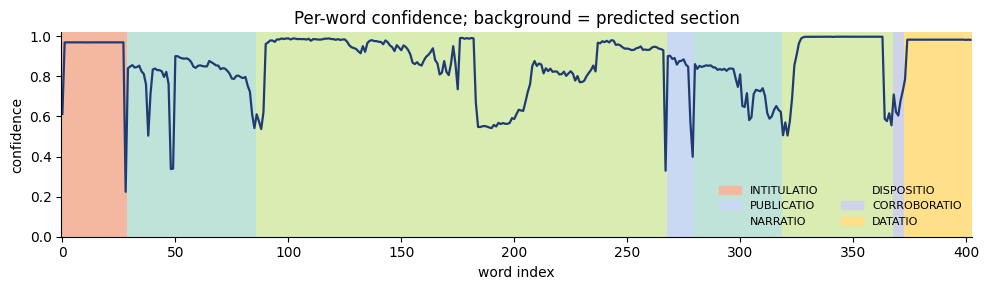

word,label,conf
Ex,B-INTITULATIO,0.22
Alioquin,B-DISPOSITIO,0.33
"didicimus,",B-PUBLICATIO,0.34
quomodo,B-NARRATIO,0.34
reverendissimo,B-DISPOSITIO,0.40
"Wesprimiensis,",I-NARRATIO,0.50
constitutis,I-DISPOSITIO,0.51
spiritualibus,I-DISPOSITIO,0.51
apostolicas,I-DISPOSITIO,0.54
bullas,I-NARRATIO,0.54


In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 3))
conf = [w["conf"] for w in sig_words]
for sp in sig_spans:
    ax.axvspan(sp["start_word"] - 0.5, sp["end_word"] + 0.5, color=SECTION_COLORS[sp["section"]], lw=0)
ax.plot(range(len(conf)), conf, color="#1f3b73", lw=1.6)
ax.set_xlim(-0.5, len(conf) - 0.5); ax.set_ylim(0, 1.02)
ax.set_xlabel("word index"); ax.set_ylabel("confidence")
ax.set_title("Per-word confidence; background = predicted section")
ax.grid(axis="y", color="#dddddd", lw=0.6); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
present = [s for s in SECTION_ORDER if any(sp["section"] == s for sp in sig_spans)]
ax.legend(handles=[Patch(color=SECTION_COLORS[s], label=s) for s in present], loc="lower right", ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

low = sorted(sig_words, key=lambda w: w["conf"])[:10]
pd.DataFrame(low)[["word", "label", "conf"]].style.format({"conf": "{:.2f}"}).hide(axis="index")

## 5. A Middle High German mandate: Charles IV to the city of Strasbourg
`KarlIV_Strassburg_mandate_mhg.txt` (issued at Prague, "an sand Dionisij tag", 232 words). Two things to notice:

* The documented weak point of the model: the narration (*Vns ist furgelegt, daz der Giek ... daz vns gar vmbillich dunket*) is labelled `DISPOSITIO`
  instead of `NARRATIO`. On German charters the model tends to merge the two sections.
* The three-word `PUBLICATIO` *Vns ist furgelegt* survives only without smoothing.

In [8]:
karl = open("KarlIV_Strassburg_mandate_mhg.txt", encoding="utf-8").read().strip()
karl_words = seg.predict_words(karl)
print("raw spans"); show(smooth_spans(collapse_spans(karl_words), 0))
print("\nsmoothed (min_span_words=5)"); show(smooth_spans(collapse_spans(karl_words), 5))
display(HTML(to_html(karl, smooth_spans(collapse_spans(karl_words), 0), title="Charles IV to the city of Strasbourg")))

raw spans
INTITULATIO    43 words  conf 0.96  Wir Karl von gots gnaden Romischer keiser zu allen zeiten merer des reichs vnd kunig zu Beheim embieten . ....
PUBLICATIO      3 words  conf 0.86  Vns ist furgelegt,
DISPOSITIO    167 words  conf 0.99  daz der Giek, der von Rapoltstein diener, vnsern vnd des reichs lieben getrewen, Prendlein, Wildrichs diene...
DATATIO        19 words  conf 0.97  Geben zu Prag an sand Dionisij tag, vnser reiche in dem dreuzehenden vnd des keisertums in dem vierden jare.

smoothed (min_span_words=5)
INTITULATIO    46 words  conf 0.96  Wir Karl von gots gnaden Romischer keiser zu allen zeiten merer des reichs vnd kunig zu Beheim embieten . ....
DISPOSITIO    167 words  conf 0.99  daz der Giek, der von Rapoltstein diener, vnsern vnd des reichs lieben getrewen, Prendlein, Wildrichs diene...
DATATIO        19 words  conf 0.97  Geben zu Prag an sand Dionisij tag, vnser reiche in dem dreuzehenden vnd des keisertums in dem vierden jare.


## 6. A long notarial instrument and the sliding window: Barletta, 5 December 1417
`Barletta_1417_XII_05_notarial_instrument.txt` has 1,717 words, far more than the model's 512-token context. The wrapper tokenises the text into
overlapping windows (stride 128), scores them in one batch and lets every window vote for the words it covers.

The genre is also different from the royal diplomas of the training data: a notarial instrument opens with the invocation and the dating clause,
continues with the notary's `INTITULATIO` and alternates narrative and dispositive passages. The raw output has many short fragments, which is
what the smoothing step is for.

In [9]:
bar = open("Barletta_1417_XII_05_notarial_instrument.txt", encoding="utf-8").read().strip()
words = bar.split()
n_sub = len(seg.tokenizer(words, is_split_into_words=True)["input_ids"])
n_win = len(seg.tokenizer(words, is_split_into_words=True, truncation=True, max_length=512, stride=128,
                          return_overflowing_tokens=True)["input_ids"])
t0 = time.time(); bar_words = seg.predict_words(bar); dt = time.time() - t0
print(f"{len(words)} words = {n_sub} subword tokens -> {n_win} windows, {dt:.2f} s on {seg.device}")

rows = [{"min_span_words": m, "spans": len(smooth_spans(collapse_spans(bar_words), m))} for m in (0, 2, 3, 5, 8, 12)]
display(pd.DataFrame(rows).style.hide(axis="index"))

print("first and last spans (min_span_words=5):")
bar_spans = smooth_spans(collapse_spans(bar_words), 5)
show(bar_spans[:6], width=90); print("..."); show(bar_spans[-3:], width=90)

1717 words = 3121 subword tokens -> 8 windows, 0.13 s on cuda


min_span_words,spans
0,42
2,28
3,22
5,20
8,20
12,16


first and last spans (min_span_words=5):
INVOCATIO       7 words  conf 0.59  In nomine domini nostri Ihesu Christi amen.
DATATIO         9 words  conf 0.89  Anno a nativitate eiusdem millesimo quadringentesimo decimo septimo, regnante
NARRATIO       35 words  conf 0.64  Serenissima domina nostra domina Iohanna secunda, Dei gratia Hungarie Ierusalem et Sici...
DATATIO         9 words  conf 0.83  amen, mense decembris, die quinto eiusdem, undecime indictionis, Baroli.
INTITULATIO    29 words  conf 0.94  Nos Nicolaus de Nucio de Barolo, regius eiusdem terre Baroli ad contractus iudex, Cobel...
PUBLICATIO      8 words  conf 0.83  et testes subscripsi presenti scripto publico instrumento fatemur,
...
CORROBORATIO   10 words  conf 0.75  In cuius rei testimonium etc. Quod scripsi ego etc. †
INTITULATIO    26 words  conf 0.65  Ego Nicolaus de Nucio, qui supra iudex, predictis interfui et me subscripsi. † Ego Anto...
CORROBORATIO   25 words  conf 0.80  testis sum. † Notarius Matheus notarii Iac

## 7. Using the model on your own texts

In [10]:
# 1) a string
for sp in seg.predict("In nomine sancte et individue trinitatis. Ego Lupoldus dei gratia dux Austrie universis Christi fidelibus "
                      "presentibus et futuris salutem. Notum sit omnibus quod ego dedi terram iuxta Danubium ecclesie sancte Marie. "
                      "Actum Vienne anno dominice incarnationis MCXLVIII.", min_span_words=0):
    print(f'{sp["section"]:<13} {sp["text"]}')

# 2) a text file
# text, spans = seg.predict_file("my_charter.txt")

# 3) command line
#    python charter_segmenter.py my_charter.txt --html out.html --json out.json

INVOCATIO     In nomine sancte et individue trinitatis.
INTITULATIO   Ego Lupoldus dei gratia dux Austrie universis Christi fidelibus presentibus et futuris salutem.
PUBLICATIO    Notum sit omnibus
NARRATIO      quod ego dedi terram iuxta Danubium ecclesie sancte Marie.
DATATIO       Actum Vienne anno dominice incarnationis MCXLVIII.


### Without the wrapper
The checkpoint is a standard `BertForTokenClassification`, so three lines of plain `transformers` code give per-token labels.
Read the labels from `model.config.id2label` (alphabetical order), and window the input yourself for texts above 512 tokens.

In [11]:
from transformers import AutoTokenizer, AutoModelForTokenClassification
import torch

MODEL = "ERCDiDip/charter-diplomatic-segmentation"
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForTokenClassification.from_pretrained(MODEL).eval()

words = "Wir Greiff von Gotes gnaden abbt ze Lambach veriehen und tuen chund allen den di disen prief sehent oder horent".split()
enc = tok(words, is_split_into_words=True, return_tensors="pt")
with torch.no_grad():
    pred = model(**enc).logits[0].argmax(-1).tolist()
seen = set()
for pos, w in enumerate(enc.word_ids()):
    if w is not None and w not in seen:          # first subword of each word
        seen.add(w); print(f"{words[w]:<10} {model.config.id2label[pred[pos]]}")

Wir        B-INTITULATIO
Greiff     I-INTITULATIO
von        I-INTITULATIO
Gotes      I-INTITULATIO
gnaden     I-INTITULATIO
abbt       I-INTITULATIO
ze         I-INTITULATIO
Lambach    I-INTITULATIO
veriehen   B-PUBLICATIO
und        I-PUBLICATIO
tuen       I-PUBLICATIO
chund      I-PUBLICATIO
allen      I-PUBLICATIO
den        I-PUBLICATIO
di         I-PUBLICATIO
disen      I-PUBLICATIO
prief      I-PUBLICATIO
sehent     I-PUBLICATIO
oder       I-PUBLICATIO
horent     I-PUBLICATIO


## Notes, limitations and citation

* **Sections the scheme lacks** (*inscriptio*, *salutatio*, *inscriptio* of mandates) are absorbed by their neighbours, mostly `INTITULATIO`.
* **German `NARRATIO`** is often labelled `DISPOSITIO` (section 5). The model card reports this as a capacity limit of the 117 M student.
* **Rare sections.** In the model card's full-scheme evaluation (107 charters) `SANCTIO` was not recovered and `NARRATIO` had the weakest F1 (0.80).
* **Smoothing** (default: spans under five words are merged into the previous span) removes fragments but also short true sections; use `min_span_words=0` when they matter.
* **Weak supervision.** The teacher was trained on CEI structural annotation of a limited corpus; the student inherits its errors. Check the output before using it in research.
* **Licence.** CC BY-NC 4.0, non-commercial use only.

## Citation
Kovács, T., Nicolaou, A., Atzenhofer-Baumgartner, F., Renet, N., Consolo, G., Tscherne, N., Decker, F., Vogeler, G. (2026).
*Distilled Weakly-Supervised Multi-Head Segmentation of Medieval Charters.* Hugging Face. https://doi.org/10.57967/hf/10291

Demo text of section 3: Ostrowski, A. (2021). *Automatische Erkennung und Klassifikation von Formularbestandteilen in Königsurkunden.* In: Die Historischen Grundwissenschaften heute, pp. 139–166 (corpus: github.com/AlinaOs/Structurally_Annotated_Medieval_Charters; charter FreisBm 0965_IV_03 of Monasterium.net).